In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

file = Path("Online Retail.xlsx")
if not file.exists():
    raise FileNotFoundError("Download and extract Online Retail.xlsx from the UCI link in the cell above, then place it next to this notebook.")
df = pd.read_excel(file, engine="openpyxl")
print("Original shape:", df.shape)
display(df.head())

Original shape: (541909, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


## 2. Dataset description and structure
Each row is an invoice line item. InvoiceNo identifies a transaction; StockCode identifies a product; Quantity and UnitPrice support revenue calculations. CustomerID is missing for some rows. Negative quantities and invoices starting with C often represent returns/cancellations, which require explicit handling.

In [9]:
print(df.info())

display(df.describe(include="all").T)

print("Missing values:\n", df.isna().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[ns]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 33.1+ MB
None


,count,unique,top,freq,mean,min,25%,50%,75%,max,std
InvoiceNo,541909.0,25900.0,573585.0,1114.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
StockCode,541909,4070,85123A,2313,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Description,540455,4223,WHITE HANGING HEART T-LIGHT HOLDER,2369,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Quantity,541909.0,NaN,NaN,NaN,9.55225,-80995.0,1.0,3.0,10.0,80995.0,218.081158
InvoiceDate,541909,NaN,NaN,NaN,2011-07-04 13:34:57.156386048,2010-12-01 08:26:00,2011-03-28 11:34:00,2011-07-19 17:17:00,2011-10-19 11:27:00,2011-12-09 12:50:00,NaN
UnitPrice,541909.0,NaN,NaN,NaN,4.611114,-11062.06,1.25,2.08,4.13,38970.0,96.759853
CustomerID,406829.0,NaN,NaN,NaN,15287.69057,12346.0,13953.0,15152.0,16791.0,18287.0,1713.600303
Country,541909,38,United Kingdom,495478,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Missing values:
 InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64


## 3. Clean and document choices
Remove exact duplicates. For customer-based analysis, exclude records without CustomerID (do not invent identities). Exclude cancellations, nonpositive quantities, and nonpositive prices from *purchase* analysis. Preserve original data separately; this is a documented business choice, not a claim that returns are invalid.

In [13]:
clean = df.drop_duplicates().copy()

clean["InvoiceNo"] = clean["InvoiceNo"].astype(str)

clean["Description"] = clean["Description"].astype("string").str.strip()

clean["InvoiceDate"] = pd.to_datetime(clean["InvoiceDate"], errors="coerce")

rows_after_dedup = len(clean)

clean = clean.dropna(
    subset=["CustomerID", "InvoiceDate", "StockCode", "Description"]
)

clean = clean[
    (~clean["InvoiceNo"].str.startswith("C")) &
    (clean["Quantity"] > 0) &
    (clean["UnitPrice"] > 0)
].copy()

clean["CustomerID"] = clean["CustomerID"].astype(int)

print("Original rows:", len(df))
print("After deduplication:", rows_after_dedup)
print("Clean purchase rows:", len(clean))
print("Missing values after cleaning:\n", clean.isna().sum())

Original rows: 541909
After deduplication: 536641
Clean purchase rows: 392692
Missing values after cleaning:
 InvoiceNo      0
StockCode      0
Description    0
Quantity       0
InvoiceDate    0
UnitPrice      0
CustomerID     0
Country        0
dtype: int64


## 4. Feature engineering
Create derived columns useful for analysis and later deliverables: `LineRevenue`, `PurchaseMonth`, `PurchaseHour`, `PurchaseDayOfWeek`, and `IsWeekend`. The dataset now contains at least 10 attributes.

In [14]:
clean["LineRevenue"] = clean["Quantity"] * clean["UnitPrice"]
clean["PurchaseMonth"] = clean["InvoiceDate"].dt.to_period("M").astype(str)
clean["PurchaseHour"] = clean["InvoiceDate"].dt.hour
clean["PurchaseDayOfWeek"] = clean["InvoiceDate"].dt.day_name()
clean["IsWeekend"] = clean["InvoiceDate"].dt.dayofweek >= 5
print("Cleaned dataset shape:", clean.shape)
display(clean.head())

Cleaned dataset shape: (392692, 13)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,LineRevenue,PurchaseMonth,PurchaseHour,PurchaseDayOfWeek,IsWeekend
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850,United Kingdom,15.30,2010-12,8,Wednesday,False
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34,2010-12,8,Wednesday,False
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850,United Kingdom,22.00,2010-12,8,Wednesday,False
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34,2010-12,8,Wednesday,False
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34,2010-12,8,Wednesday,False


## 5. Explore outliers without silently deleting valid large orders
Use IQR to flag unusually large line revenues. High-value purchases may be legitimate; we retain them in the cleaned export and discuss robust transformations for later modeling.

In [15]:
q1, q3 = clean["LineRevenue"].quantile([0.25, 0.75])
iqr = q3-q1
upper = q3+1.5*iqr
flagged = clean[clean["LineRevenue"] > upper]
print(f"Q1={q1:.2f}, Q3={q3:.2f}, IQR={iqr:.2f}, upper fence={upper:.2f}")
print("High-value line items flagged:",len(flagged),"of",len(clean))

Q1=4.95, Q3=19.80, IQR=14.85, upper fence=42.07
High-value line items flagged: 31231 of 392692


## 6. Exploratory visualizations

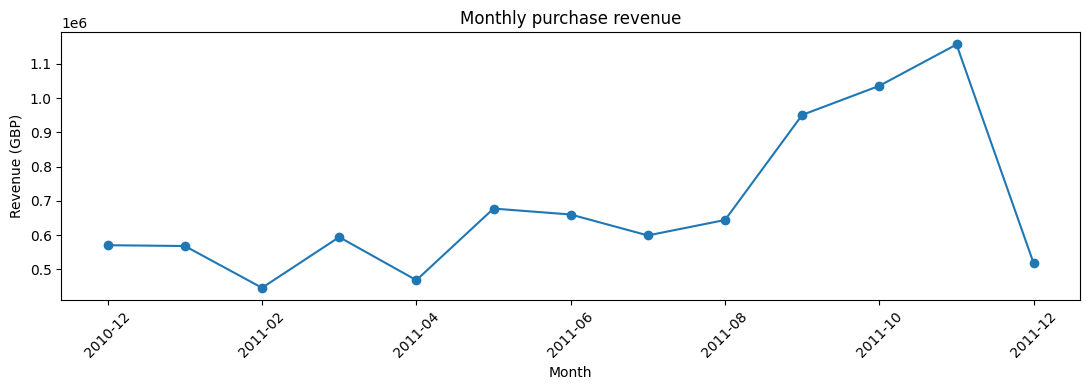

In [16]:
monthly = clean.groupby("PurchaseMonth")["LineRevenue"].sum().sort_index()
ax = monthly.plot(figsize=(11,4), marker="o", title="Monthly purchase revenue")
ax.set(xlabel="Month",ylabel="Revenue (GBP)")
plt.xticks(rotation=45);plt.tight_layout();plt.show()

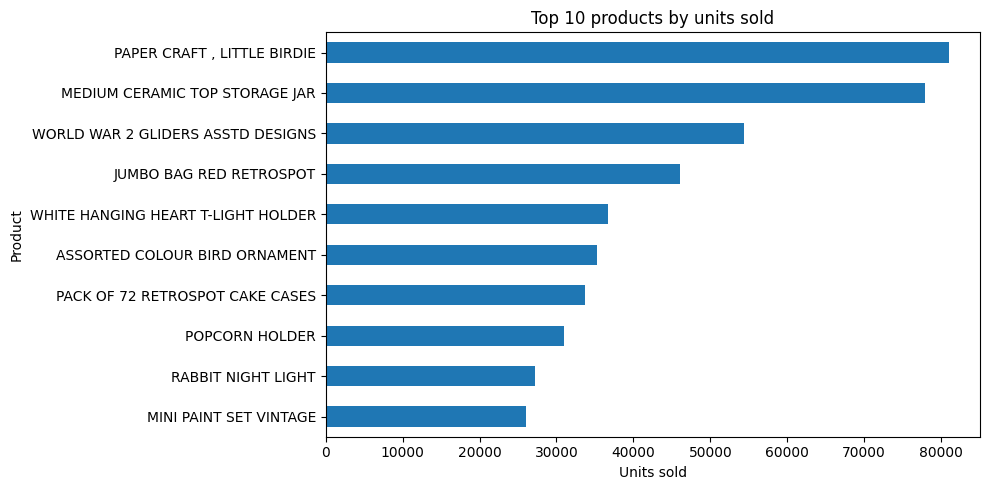

In [17]:
top = clean.groupby("Description")["Quantity"].sum().nlargest(10).sort_values()
ax = top.plot.barh(figsize=(10,5), title="Top 10 products by units sold")
ax.set(xlabel="Units sold",ylabel="Product");plt.tight_layout();plt.show()

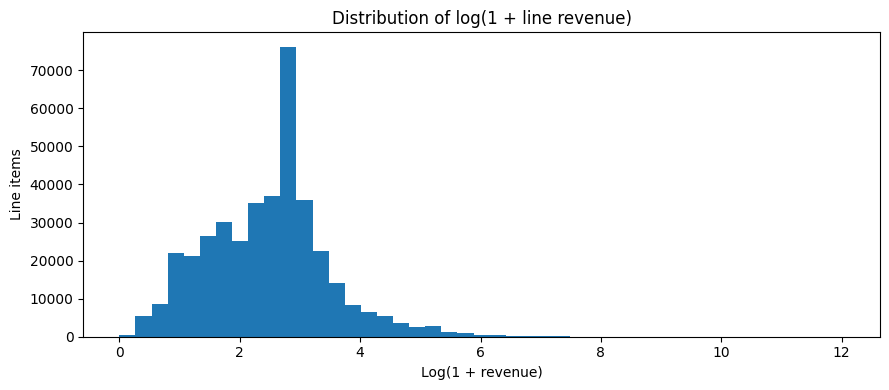

In [18]:
fig,ax=plt.subplots(figsize=(9,4))
ax.hist(np.log1p(clean["LineRevenue"]),bins=45)
ax.set(title="Distribution of log(1 + line revenue)",xlabel="Log(1 + revenue)",ylabel="Line items")
plt.tight_layout();plt.show()

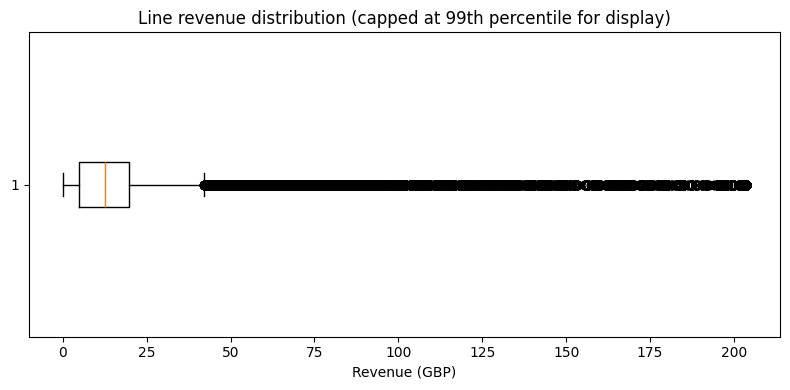

In [19]:
fig,ax=plt.subplots(figsize=(8,4))
ax.boxplot(clean["LineRevenue"].clip(upper=clean["LineRevenue"].quantile(.99)),vert=False)
ax.set(title="Line revenue distribution (capped at 99th percentile for display)",xlabel="Revenue (GBP)")
plt.tight_layout();plt.show()

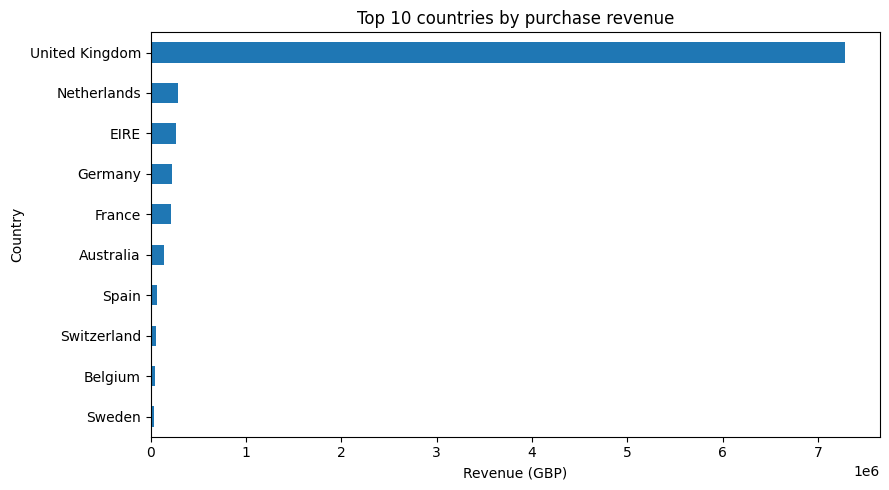

In [20]:
country = clean.groupby("Country")["LineRevenue"].sum().nlargest(10).sort_values()
ax = country.plot.barh(figsize=(9,5), title="Top 10 countries by purchase revenue")
ax.set(xlabel="Revenue (GBP)",ylabel="Country");plt.tight_layout();plt.show()

## 7. Statistics and feature relationships

,count,mean,std,min,25%,50%,75%,max
Quantity,392692.0,13.119702,180.492832,1.000,2.00,6.00,12.00,80995.00
UnitPrice,392692.0,3.125914,22.241836,0.001,1.25,1.95,3.75,8142.75
LineRevenue,392692.0,22.631500,311.099224,0.001,4.95,12.45,19.80,168469.60
PurchaseHour,392692.0,12.721532,2.276661,6.000,11.00,13.00,14.00,20.00


,Quantity,UnitPrice,LineRevenue,PurchaseHour
Quantity,1.000000,-0.004578,0.914451,-0.014665
UnitPrice,-0.004578,1.000000,0.081619,-0.000217
LineRevenue,0.914451,0.081619,1.000000,-0.013093
PurchaseHour,-0.014665,-0.000217,-0.013093,1.000000


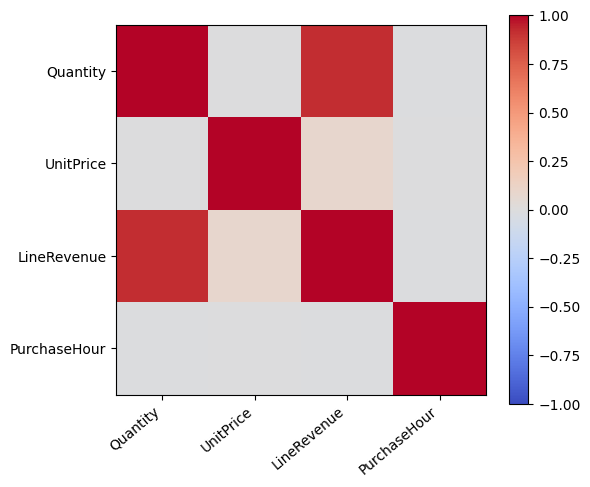

In [21]:
display(clean[["Quantity","UnitPrice","LineRevenue","PurchaseHour"]].describe().T)
correlations=clean[["Quantity","UnitPrice","LineRevenue","PurchaseHour"]].corr()
display(correlations)
fig,ax=plt.subplots(figsize=(6,5))
im=ax.imshow(correlations, vmin=-1,vmax=1,cmap="coolwarm")
ax.set_xticks(range(len(correlations.columns)),correlations.columns,rotation=40,ha="right")
ax.set_yticks(range(len(correlations.index)),correlations.index)
fig.colorbar(im,ax=ax);plt.tight_layout();plt.show()

## 8. Customer-level features for later deliverables
One row per customer provides frequency, total spending, average line revenue, and number of distinct products. Later deliverables must avoid using features that leak the target being predicted.

In [22]:
customer = clean.groupby("CustomerID").agg(
    TotalSpend=("LineRevenue","sum"),
    PurchaseLines=("InvoiceNo","size"),
    InvoiceCount=("InvoiceNo","nunique"),
    UniqueProducts=("StockCode","nunique"),
    AvgLineRevenue=("LineRevenue","mean")
).reset_index()
print("Customer-level shape:",customer.shape)
display(customer.head())
clean.to_csv("online_retail_cleaned.csv",index=False)
customer.to_csv("online_retail_customer_features.csv",index=False)
print("Saved cleaned transaction and customer feature CSVs.")

Customer-level shape: (4338, 6)


,CustomerID,TotalSpend,PurchaseLines,InvoiceCount,UniqueProducts,AvgLineRevenue
0,12346,77183.60,1,1,1,77183.600000
1,12347,4310.00,182,7,103,23.681319
2,12348,1797.24,31,4,22,57.975484
3,12349,1757.55,73,1,73,24.076027
4,12350,334.40,17,1,17,19.670588


Saved cleaned transaction and customer feature CSVs.


In [ ]:
## 9. Interpretation — 
9. Interpretation and Key Findings

9.1 Monthly Sales Analysis

The monthly revenue analysis identified November 2011 as the highest-revenue month, generating £1,156,205.61 in sales. This finding indicates particularly strong purchasing activity during November. Seasonal demand may have contributed to this increase, although additional comparisons across months and years would be needed to confirm a recurring seasonal pattern.

9.2 Top-Selling Products

The highest-selling product by quantity was PAPER CRAFT, LITTLE BIRDIE, with 80,995 units sold.

This demonstrates that certain products contribute significantly to total sales volume. However, high sales volume does not necessarily indicate the highest revenue because products differ in unit price. Future analysis should compare total quantity sold with revenue generated by individual products.

9.3 Revenue Distribution and Outlier Detection

The analysis identified 31,231 high-value transaction-line observations exceeding the upper threshold calculated using the Interquartile Range (IQR) method.

These observations may represent unusually large purchases, bulk orders, or high-priced products. Rather than automatically removing them, the analysis retained these observations because they may contain meaningful information about purchasing behavior.

The large number of flagged observations also highlights the importance of examining the revenue distribution before applying predictive models.

9.4 Feature Relationships and Correlation Analysis

The correlation analysis produced the following results:

Feature Relationship

Correlation

Interpretation

Quantity vs. Revenue

0.914451

Strong positive correlation

UnitPrice vs. Revenue

0.081619

Weak positive correlation

Quantity vs. UnitPrice

-0.004578

Negligible linear correlation

The strongest relationship was observed between Quantity and Revenue, with a correlation coefficient of 0.914451. This indicates that transaction lines containing larger quantities generally generate higher revenue.

The correlation between UnitPrice and Revenue was relatively weak at 0.081619, suggesting that unit price alone has limited linear association with transaction-line revenue.

Quantity and UnitPrice showed almost no linear correlation.

Because revenue is calculated as Quantity multiplied by UnitPrice, the strong relationship between Quantity and Revenue is partly mathematical. This is important when selecting predictive features to avoid data leakage.

9.5 Implications for Future Modeling

The cleaned dataset provides a foundation for the next stages of the data mining project.

Deliverable 2 — Regression Modeling: Historical customer purchasing behavior, transaction frequency, average order value, and other engineered features can be used to predict future customer spending. Training and testing periods should be separated chronologically to reduce data leakage.

Deliverable 3 — Classification, Clustering, and Association Rule Mining: Classification algorithms can predict future purchasing behavior, while clustering techniques can identify customer groups based on spending patterns and transaction frequency. Association rule mining can identify products frequently purchased together.

These approaches can support customer segmentation, sales forecasting, inventory planning, and targeted marketing strategies.

9.6 Challenges and Data Cleaning Decisions

Several data quality challenges were addressed during preprocessing.

Missing Customer Identifiers: Records without CustomerID were excluded from customer-level analysis because customer identities could not be reliably reconstructed.

Duplicate Transactions: Exact duplicate records were removed to prevent repeated observations from distorting the analysis.

Cancellations and Returns: Canceled invoices and records containing nonpositive quantities or prices were excluded from positive-purchase analysis to improve the consistency of revenue calculations.

Revenue Outliers: A total of 31,231 high-value observations were identified using the IQR method. These records were retained because they may represent legitimate purchases.

Feature Engineering: Additional attributes, including revenue and transaction-date features, were created to support exploratory analysis and future modeling.

9.7 Conclusion

The exploratory analysis revealed several important patterns in the Online Retail dataset. November 2011 generated the highest monthly revenue at £1,156,205.61, while PAPER CRAFT, LITTLE BIRDIE recorded the highest sales quantity of 80,995 units.

The correlation analysis showed a strong positive relationship between Quantity and Revenue (0.914451), and the IQR method identified 31,231 high-value observations.

Overall, the cleaning and exploratory analysis established a more consistent dataset for subsequent regression, classification, clustering, and association rule mining tasks.

In [4]:
print("Hello! Jupyter is working")
2 + 2

Hello! Jupyter is working


4

In [23]:
# Highest-revenue month
print("Highest revenue month:")
print(
    clean.assign(
        Month=clean["InvoiceDate"].dt.to_period("M"),
        Revenue=clean["Quantity"] * clean["UnitPrice"]
    ).groupby("Month")["Revenue"].sum().sort_values(ascending=False).head(1)
)

# Top-selling product
print("\nTop-selling product:")
print(
    clean.groupby("Description")["Quantity"]
    .sum().sort_values(ascending=False).head(1)
)

# Revenue outliers using IQR
revenue = clean["Quantity"] * clean["UnitPrice"]
q1 = revenue.quantile(0.25)
q3 = revenue.quantile(0.75)
iqr = q3 - q1
upper = q3 + 1.5 * iqr

print("\nNumber of high-value outliers:", (revenue > upper).sum())

# Correlation matrix
print("\nCorrelation matrix:")
print(
    clean.assign(Revenue=revenue)[
        ["Quantity", "UnitPrice", "Revenue"]
    ].corr()
)

Highest revenue month:
Month
2011-11    1156205.61
Freq: M, Name: Revenue, dtype: float64

Top-selling product:
Description
PAPER CRAFT , LITTLE BIRDIE    80995
Name: Quantity, dtype: int64

Number of high-value outliers: 31231

Correlation matrix:
           Quantity  UnitPrice   Revenue
Quantity   1.000000  -0.004578  0.914451
UnitPrice -0.004578   1.000000  0.081619
Revenue    0.914451   0.081619  1.000000
